### Configuración del controlador e inicio de sesión Spark

El conector JDBC de MySQL (Connector/J 9.7.0) se descarga la primera vez en `~/.miid4103/jars` (requiere internet) y lo reutilizan los demás notebooks.

In [1]:
import os
import sys

# En la máquina virtual ya está todo instalado
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_CODESPACES = os.environ.get('CODESPACES') == 'true'

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark==4.2.0 pandas==2.3.3 numpy==2.5.3 pyarrow==25.0.1 matplotlib==3.11.2 fg-data-profiling==4.20.0 scipy==1.18.1 seaborn==0.13.2

if IN_COLAB:
    # Spark 4 requiere Java 17 o superior
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'

ENVIRONMENT = 'colab' if IN_COLAB else 'codespaces' if IN_CODESPACES else 'local'
print(f'Entorno detectado: {ENVIRONMENT}')

from pyspark.sql import SparkSession
from pyspark.sql import functions
from pyspark.sql.types import StructType
from pyspark.sql.types import FloatType, StringType, IntegerType, DateType
from pyspark.sql.functions import udf, col, length, isnan, when, count
import pyspark.sql.functions as f
from datetime import datetime
from pyspark.sql import types as t

from data_profiling import ProfileReport

import matplotlib.pyplot as plt
import numpy as np

Entorno detectado: local


In [2]:
from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR}')

Conector JDBC: /Users/milemirke/.miid4103/jars/mysql-connector-j-9.7.0.jar


In [3]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.2 en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

# En macOS con Java de Homebrew el kernel de Jupyter no siempre encuentra Java (error JAVA_GATEWAY_EXITED)
if 'JAVA_HOME' not in os.environ and os.path.exists('/usr/libexec/java_home'):
    import subprocess
    os.environ['JAVA_HOME'] = subprocess.run(['/usr/libexec/java_home'], capture_output=True, text=True).stdout.strip()

spark = (SparkSession.builder
         .master('local[*]')
         .appName('MIID4103-NB02')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    # comportamiento de Spark 3.5
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/03 20:59:53 WARN Utils: Your hostname, MacBook-Air-de-Milena.local, resolves to a loopback address: 127.0.0.1; using 192.168.20.42 instead (on interface en0)
26/11/03 20:59:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


26/11/03 20:59:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [4]:
db_host = '157.253.236.120'
db_port = 8080
db_user = 'DB_202615_al_roa '.strip()
db_psswd = '202626538'

if not db_user or not db_psswd:
    raise ValueError('Complete db_user y db_psswd antes de continuar')
jdbc_opciones = 'useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'
db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/RaSaTransaccional?{jdbc_opciones}'

# En Colab, suba los archivos a /content/
PATH = '/content/' if ENVIRONMENT == 'colab' else './'

OUT = Path('/content/salidas') if ENVIRONMENT == 'colab' else Path.home() / 'MIID4103' / 'salidas'
OUT.mkdir(parents=True, exist_ok=True)

# Conexión fuente de datos

In [5]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

In [6]:
# Conexión tabla Fuente Areas De servicio
sql_FuenteAreas = 'RaSaTransaccional.FuenteAreasDeServicio_Copia_E'

# Conexión tabla Fuente condiciones de pago
sql_FuenteCondicionesPago = 'RaSaTransaccional.FuenteCondicionesDePago_Copia_E'

# Conexión tabla Fuente planes beneficio
sql_FuentePlanesBeneficio = 'RaSaTransaccional.FuentePlanesBeneficio_Copia_E'

# Conexión tabla Fuente tipos beneficio
sql_FuenteTiposBeneficio = 'RaSaTransaccional.FuenteTiposBeneficio_Copia_E'


In [7]:
FuenteAreas = obtener_dataframe_de_bd(db_connection_string, sql_FuenteAreas, db_user, db_psswd)

FuenteCondicionesPago = obtener_dataframe_de_bd(db_connection_string, sql_FuenteCondicionesPago, db_user, db_psswd)

FuentePlanesBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuentePlanesBeneficio, db_user, db_psswd)

FuenteTiposBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuenteTiposBeneficio, db_user, db_psswd)

In [8]:
FuenteAreas.show(5) 
FuenteCondicionesPago.show(5)
FuentePlanesBeneficio.show(5)
FuenteTiposBeneficio.show(5)

+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|          Condado|    Estado|PoblacionAct| Area|Densidad|Fecha|
+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|         100622017|New Jersey - Medi...|        34005|Burlington County|New Jersey|    464269.0|805.0|   577.0| 2017|
|         101012018|New Jersey - Medi...|        34031|   Passaic County|New Jersey|    518117.0|185.0|  2801.0| 2018|
|          10132017|BlueOptions16842F...|        12031|     Duval County|   Florida|    999935.0|774.0|  1292.0| 2017|
|         101982018|New Jersey - Medi...|        34003|    Bergen County|New Jersey|    953819.0|234.0|  4076.0| 2018|
|         102012017|New Jersey - Medi...|        34021|    Mercer County|New Jersey|    385898.0|226.0|  1708.0| 2017|
+------------------+--------------------+-------

+---------------------+--------------------+--------+
|IdCondicionesDePago_T|         Descripcion|    Tipo|
+---------------------+--------------------+--------+
|                  187|Copay with deduct...|  Copago|
|                  204|       Copay per Day|  Copago|
|                   45|         Coinsurance|Coseguro|
|                   85|Copay per Day bef...|  Copago|
|                   18|No Charge after d...|Coseguro|
+---------------------+--------------------+--------+
only showing top 5 rows


+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|         IdPlan_T|     Fecha|IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|              640|          10382017|                       34|                         27|                3|16842FL0070128-03|2017-12-31|        16842|          0|           50|            35|
|              225|          31512017|                      238|                         45|                2|29418TX0140002-04|2017-12-31|        29418|          0|            0|          NULL|
|              190|      

+-----------------+--------------------+--------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|              Nombre|     UnidadDelLimite|EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+--------------------+--------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|              565|Nutritional Couns...|                    |   No|                  Yes|                     No|                                      No|                                    Yes| 2017|
|              795|Rehabilitative Sp...|Days per Benefit ...|  Yes|                  Yes|                    Yes|                                      No|                                    Yes| 2

# Análisis de calidad de datos: FuentePlanesBeneficio y FuenteTiposBeneficio


# 1. FuentePlanesBeneficio

## Entendimiento general de los datos
Antes de evaluar la calidad se revisa la estructura (esquema), el tamaño y qué representa una fila de cada fuente.

In [9]:
FuentePlanesBeneficio.printSchema()

root
 |-- IdTipoBeneficio_T: long (nullable = true)
 |-- IdAreaDeServicio_T: long (nullable = true)
 |-- IdCondicionDePagoCopago_T: integer (nullable = true)
 |-- IdCondicionDePagoCoseguro_T: integer (nullable = true)
 |-- IdNivelServicio_T: integer (nullable = true)
 |-- IdPlan_T: string (nullable = true)
 |-- Fecha: string (nullable = true)
 |-- IdProveedor_T: integer (nullable = true)
 |-- valorCopago: integer (nullable = true)
 |-- valorCoseguro: integer (nullable = true)
 |-- cantidadLimite: integer (nullable = true)



In [10]:
print('FuentePlanesBeneficio (filas, columnas):', (FuentePlanesBeneficio.count(), len(FuentePlanesBeneficio.columns)))

FuentePlanesBeneficio (filas, columnas): (36036, 11)


**¿Qué es una fila de cada fuente?**
- **FuentePlanesBeneficio:** un tipo de beneficio (`IdTipoBeneficio_T`) ofrecido dentro de un plan (`IdPlan_T`) de un proveedor (`IdProveedor_T`), para un nivel de servicio (`IdNivelServicio_T`) y un año (`Fecha`), con sus condiciones de pago (copago y coseguro) y, cuando aplica, una cantidad límite.

In [11]:
FuentePlanesBeneficio.select('valorCopago', 'valorCoseguro', 'cantidadLimite', 'IdNivelServicio_T').summary().show()

+-------+------------------+------------------+-----------------+------------------+
|summary|       valorCopago|     valorCoseguro|   cantidadLimite| IdNivelServicio_T|
+-------+------------------+------------------+-----------------+------------------+
|  count|             36036|             36036|             5465|             36036|
|   mean| 9.778416028416029| 24.29279054279054|129.3313815187557|1.9995282495282496|
| stddev|100.41137967701272|36.959755494458506|951.2795862330698|0.8173400355652516|
|    min|                 0|                 0|                1|                 1|
|    25%|                 0|                 0|                1|                 1|
|    50%|                 0|                 0|               25|                 2|
|    75%|                 0|                50|               40|                 3|
|    max|              3500|               100|            30000|                 3|
+-------+------------------+------------------+-----------------+

## Completitud
Se crea la función `contar_vacios`, además de los nulos, las **cadenas vacías** en las columnas de texto: un texto vacío no es nulo para Spark, pero tampoco aporta información.

In [12]:
def contar_vacios(df):
    total = df.count()
    resultados = {}
    for c, tipo in df.dtypes:
        condicion = col(c).isNull()
        if tipo == 'string':
            condicion = condicion | (f.trim(col(c)) == '')
        vacios = df.filter(condicion).count()
        if vacios != 0:
            print(f'número de vacíos para columna {c}: {vacios} ({vacios / total:.1%})')
            resultados[c] = vacios
    return resultados

print('FuentePlanesBeneficio:')
vacios_planes = contar_vacios(FuentePlanesBeneficio)

FuentePlanesBeneficio:
número de vacíos para columna IdTipoBeneficio_T: 2086 (5.8%)
número de vacíos para columna IdAreaDeServicio_T: 2041 (5.7%)
número de vacíos para columna IdPlan_T: 2053 (5.7%)
número de vacíos para columna cantidadLimite: 30571 (84.8%)


In [13]:
# ¿Los faltantes ocurren en las mismas filas?
FuentePlanesBeneficio.select(
    f.sum(when(col('IdTipoBeneficio_T').isNull() & col('IdAreaDeServicio_T').isNull(), 1).otherwise(0)).alias('tipo_y_area_nulos'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() & (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('tipo_nulo_y_plan_vacio'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() | col('IdAreaDeServicio_T').isNull() | (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('filas_con_algun_faltante')
).show()

+-----------------+----------------------+------------------------+
|tipo_y_area_nulos|tipo_nulo_y_plan_vacio|filas_con_algun_faltante|
+-----------------+----------------------+------------------------+
|                0|                     0|                    6180|
+-----------------+----------------------+------------------------+



**Conclusiones de completitud**

*FuentePlanesBeneficio*
- `IdTipoBeneficio_T` tiene 2.086 nulos (5,8 %) e `IdAreaDeServicio_T` tiene 2.041 (5,7 %). Sin el tipo de beneficio la fila no se puede relacionar con el catálogo, y sin área no se sabe dónde aplica el plan.
- `IdPlan_T` no tiene nulos, pero sí 2.053 **cadenas vacías** (5,7 %). Este faltante "escondido" no lo detecta `isNull()` ni la herramienta de perfilamiento.
- `cantidadLimite` está vacía en 30.571 filas (84,8 %). Esto puede ser esperado si la mayoría de beneficios no tienen límite cuantitativo, pero hay que confirmarlo con el negocio.
- Los faltantes de tipo, área y plan nunca coinciden en la misma fila: en total 6.180 filas (17,1 %) tienen alguno. Eliminar todas las filas incompletas implicaría perder ese porcentaje de los datos.
- `Fecha` tampoco tiene nulos, pero 2.052 filas traen `1920-12-31`, que parece un valor por defecto en lugar de un dato real (ver Validez).

## Unicidad
Primero se buscan duplicados totales (filas idénticas) y después duplicados por la llave de cada tabla, es decir, la combinación de atributos que debería identificar una fila.

In [14]:
for nombre, df in [('FuentePlanesBeneficio', FuentePlanesBeneficio), ('FuenteTiposBeneficio', FuenteTiposBeneficio)]:
    total, distintos = df.count(), df.distinct().count()
    print(f'{nombre}: {total} filas, {distintos} distintas, {total - distintos} duplicados totales ({(total - distintos) / total:.1%})')

FuentePlanesBeneficio: 36036 filas, 27543 distintas, 8493 duplicados totales (23.6%)
FuenteTiposBeneficio: 849 filas, 578 distintas, 271 duplicados totales (31.9%)


En **FuentePlanesBeneficio** una fila debería ser única por plan, tipo de beneficio, año y nivel de servicio (`IdPlan_T`, `IdTipoBeneficio_T`, `Fecha`, `IdNivelServicio_T`). Se revisa sobre las filas sin duplicados totales y con plan informado:

In [17]:
planes_unicos = FuentePlanesBeneficio.distinct()
llave_planes = ['IdPlan_T', 'IdTipoBeneficio_T', 'Fecha', 'IdNivelServicio_T']
repetidas = planes_unicos.filter(f.trim(col('IdPlan_T')) != '').groupBy(llave_planes).count().filter(col('count') > 1)
filas_involucradas = repetidas.agg(f.sum('count')).first()[0]
print('Combinaciones de llave repetidas:', repetidas.count())
print('Filas involucradas:', filas_involucradas, '| filas sobrantes:', filas_involucradas - repetidas.count())
repetidas.orderBy(col('count').desc()).show(5)

Combinaciones de llave repetidas: 542


Filas involucradas: 2043 | filas sobrantes: 1501
+-----------------+-----------------+----------+-----------------+-----+
|         IdPlan_T|IdTipoBeneficio_T|     Fecha|IdNivelServicio_T|count|
+-----------------+-----------------+----------+-----------------+-----+
|40047MI0070001-00|             NULL|2017-12-31|                2|   16|
|40047MI0070001-00|             NULL|2017-12-31|                1|   15|
|40047MI0070001-00|             NULL|2017-12-31|                3|   14|
|74917MI0010003-01|              825|2017-12-31|                1|   12|
|74917MI0010003-01|              825|2017-12-31|                3|   10|
+-----------------+-----------------+----------+-----------------+-----+
only showing top 5 rows


In [18]:
planes_unicos.filter((col('IdPlan_T') == '40047MI0070001-00') & (col('IdTipoBeneficio_T') == 5) & (col('Fecha') == '2017-12-31')) \
    .orderBy('IdNivelServicio_T').show()

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|         IdPlan_T|     Fecha|IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|                5|          51632017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|          52222017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|      

**Conclusiones de unicidad**
- **FuentePlanesBeneficio** tiene 8.493 filas completamente repetidas (23,6 %), que deben eliminarse. Después de quitarlas, todavía hay 542 combinaciones de plan, tipo, año y nivel de servicio repetidas (2.043 filas, 1.501 sobrantes). En el ejemplo del plan `40047MI0070001-00` las filas repetidas solo cambian en `IdAreaDeServicio_T`. Esto sugiere que la llave real incluye el área de servicio, pero hay que confirmarlo con el negocio.

## Validez
Se revisa el formato de las fechas y de los identificadores de texto, el dominio de las variables categóricas y el rango de las variables numéricas.

### Formato de `Fecha` en FuentePlanesBeneficio
Se usa una expresión regular para el formato `YYYY-MM-DD`, como en el tutorial.

In [19]:
regex_fecha = r'^[0-2]\d{3}-(0[1-9]|1[0-2])-(0[1-9]|[1-2][0-9]|3[0-1])$'
no_cumplen = FuentePlanesBeneficio.filter(~col('Fecha').rlike(regex_fecha))
print('Filas con Fecha fuera del formato YYYY-MM-DD:', no_cumplen.count())
FuentePlanesBeneficio.groupBy('Fecha').count().orderBy('Fecha').show()

Filas con Fecha fuera del formato YYYY-MM-DD: 2056
+-----------+-----+
|      Fecha|count|
+-----------+-----+
| 1920-12-31| 2052|
| 2017-12-31|16134|
| 2018-12-31|15794|
|Dec 31,2017| 1029|
|Dec 31,2018| 1027|
+-----------+-----+



### Formato de `IdPlan_T`
Los identificadores de plan siguen el patrón: 5 dígitos del proveedor, 2 letras del estado, 7 dígitos, un guion y 2 dígitos de la variante (ej. `16842FL0070128-03`).

In [20]:
regex_plan = r'^\d{5}[A-Z]{2}\d{7}-\d{2}$'
FuentePlanesBeneficio.filter(~col('IdPlan_T').rlike(regex_plan)).groupBy('IdPlan_T').count().show()

+--------+-----+
|IdPlan_T|count|
+--------+-----+
|        | 2053|
+--------+-----+



### Rango de las variables numéricas de FuentePlanesBeneficio
`valorCoseguro` es un porcentaje (0 a 100), `valorCopago` es un valor en dinero y `cantidadLimite` es una cantidad positiva. Además se revisan los dominios de los identificadores de condición de pago y de nivel de servicio.

In [23]:
FuentePlanesBeneficio.select(
    f.sum(when((col('valorCoseguro') < 0) | (col('valorCoseguro') > 100), 1).otherwise(0)).alias('coseguro_fuera_0_100'),
    f.sum(when(col('valorCopago') < 0, 1).otherwise(0)).alias('copago_negativo'),
    f.sum(when(col('valorCopago') > 100, 1).otherwise(0)).alias('copago_mayor_100'),
    f.sum(when(col('cantidadLimite') <= 0, 1).otherwise(0)).alias('limite_no_positivo'),
    f.sum(when(col('cantidadLimite') > 100, 1).otherwise(0)).alias('limite_mayor_100')
).show()

for c in ['IdNivelServicio_T', 'IdCondicionDePagoCopago_T', 'IdCondicionDePagoCoseguro_T']:
    FuentePlanesBeneficio.groupBy(c).count().orderBy(col('count').desc()).show(20)

+--------------------+---------------+----------------+------------------+----------------+
|coseguro_fuera_0_100|copago_negativo|copago_mayor_100|limite_no_positivo|limite_mayor_100|
+--------------------+---------------+----------------+------------------+----------------+
|                   0|              0|             441|                 0|             319|
+--------------------+---------------+----------------+------------------+----------------+

+-----------------+-----+
|IdNivelServicio_T|count|
+-----------------+-----+
|                1|12045|
|                3|12028|
|                2|11963|
+-----------------+-----+

+-------------------------+-----+
|IdCondicionDePagoCopago_T|count|
+-------------------------+-----+
|                      238|18123|
|                       34|16364|
|                       51|  612|
|                      207|  325|
|                      153|  290|
|                      170|  124|
|                      102|   50|
|               

+---------------------------+-----+
|IdCondicionDePagoCoseguro_T|count|
+---------------------------+-----+
|                         45|22762|
|                         27| 8354|
|                         36| 3785|
|                         18|  664|
|                          9|  471|
+---------------------------+-----+



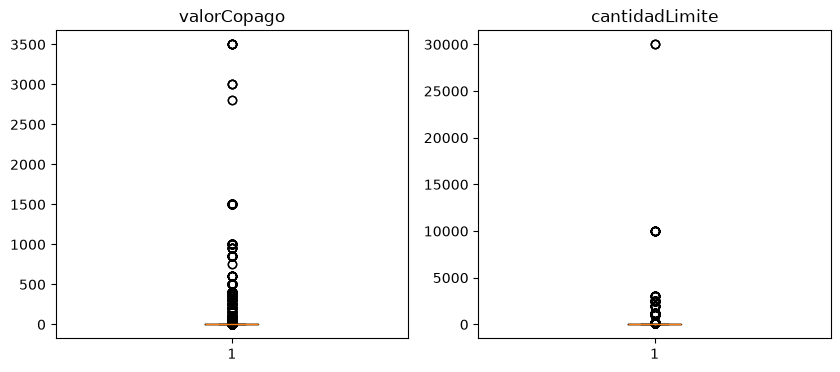

+--------------+-----+
|cantidadLimite|count|
+--------------+-----+
|         30000|    3|
|         10000|   16|
|          3000|   23|
|          2500|   60|
|          2000|   24|
+--------------+-----+
only showing top 5 rows


In [24]:
%matplotlib inline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.set_title('valorCopago')
ax1.boxplot([row[0] for row in FuentePlanesBeneficio.select('valorCopago').dropna().collect()])
ax2.set_title('cantidadLimite')
ax2.boxplot([row[0] for row in FuentePlanesBeneficio.select('cantidadLimite').dropna().collect()])
plt.show()

FuentePlanesBeneficio.groupBy('cantidadLimite').count().orderBy(col('cantidadLimite').desc()).show(5)

**Conclusiones de validez**
- **Fecha (planes):** 2.056 filas traen otro formato (`Dec 31,2017` y `Dec 31,2018`). Es solo un problema de formato y se puede estandarizar a `YYYY-MM-DD`. Además, 2.052 filas tienen `1920-12-31`: el formato es correcto pero el valor no tiene sentido, se recomienda validar con la empresa si este es un error en la escritura o identificar porque sale este registro, porque los demás datos son de 2017 y 2018. Es un valor por defecto que esconde un faltante. En Consistencia se muestra que el año real se puede recuperar.
- **IdPlan_T:** todos los planes informados cumplen el patrón. Solo fallan los 2.053 vacíos.
- **Rangos:** `valorCoseguro` está siempre entre 0 y 100 y no hay valores negativos. `valorCopago` es 0 en la mayoría de filas, pero 441 filas superan 100 (hasta 3.500). `cantidadLimite` supera 100 en 319 filas y llega hasta 30.000. Estos valores extremos pueden ser válidos si el límite está en dólares (ver `UnidadDelLimite` = `Dollars per ...`), así que se reportan como atípicos para confirmar, no como errores.
- Los dominios de `IdNivelServicio_T` (1, 2, 3) y de las condiciones de pago son pequeños y no muestran valores extraños. Habría que validarlos contra `FuenteCondicionesDePago`.

## Consistencia
Se revisa la coherencia **dentro de una fila** (atributos que dependen entre sí) y **entre fuentes** (integridad referencial entre planes y tipos de beneficio).

### Proveedor contra plan
Los 5 primeros dígitos de `IdPlan_T` corresponden al proveedor, así que deberían coincidir con `IdProveedor_T`.

In [25]:
planes_informados = FuentePlanesBeneficio.filter(f.trim(col('IdPlan_T')) != '')
print('Planes informados:', planes_informados.count())
print('Proveedor distinto al prefijo del plan:',
      planes_informados.filter(f.substring('IdPlan_T', 1, 5) != col('IdProveedor_T').cast('string')).count())

Planes informados: 33983
Proveedor distinto al prefijo del plan: 0


### Área de servicio contra año
Los últimos 4 dígitos de `IdAreaDeServicio_T` parecen corresponder al año del plan (ej. área `10382017` con fecha `2017-12-31`). Se compara ese sufijo con el año de `Fecha`:

In [26]:
areas = FuentePlanesBeneficio.filter(col('IdAreaDeServicio_T').isNotNull()) \
    .withColumn('sufijo_area', f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)) \
    .withColumn('anio_fecha', f.regexp_extract('Fecha', r'(\d{4})', 1))
areas.groupBy('anio_fecha', 'sufijo_area').count().orderBy('anio_fecha', 'sufijo_area').show()

+----------+-----------+-----+
|anio_fecha|sufijo_area|count|
+----------+-----------+-----+
|      1920|       2017|  986|
|      1920|       2018| 1066|
|      2017|       2017|15019|
|      2017|       4035| 1066|
|      2018|       2018|14849|
|      2018|       4036| 1009|
+----------+-----------+-----+



**Conclusiones de consistencia**
- **Proveedor contra plan:** todas las filas con plan informado son coherentes, porque el prefijo de `IdPlan_T` siempre coincide con `IdProveedor_T`. Esto también muestra que `IdProveedor_T` es redundante con el plan.
- **Área contra año:** en 29.868 filas el sufijo del área coincide con el año de `Fecha`. Hay tres excepciones:
  - Las 2.052 filas con `Fecha = 1920-12-31` tienen sufijo 2017 (986) o 2018 (1.066) en el área. Esto confirma que 1920 es un valor por defecto y que el año real se puede recuperar del área.
  - 1.066 filas de 2017 tienen sufijo 4035 y 1.009 filas de 2018 tienen sufijo 4036 (4035 = 2017 + 2018 y 4036 = 2018 + 2018). Esto sugiere un error al construir la llave del área que se debe consultar.
  - Además, el área viene como entero, así que pierde los ceros a la izquierda y tiene longitudes de 5 a 9 dígitos.

# 2. FuenteTiposBeneficio

## Entendimiento general de los datos

In [9]:
FuenteTiposBeneficio.printSchema()

root
 |-- IdTipoBeneficio_T: integer (nullable = true)
 |-- Nombre: string (nullable = true)
 |-- UnidadDelLimite: string (nullable = true)
 |-- EsEHB: string (nullable = true)
 |-- EstaCubiertaPorSeguro: string (nullable = true)
 |-- TieneLimiteCuantitativo: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoDentroDeLaRed: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoFueraDeLaRed: string (nullable = true)
 |-- Fecha: integer (nullable = true)



In [10]:
print('FuenteTiposBeneficio (filas, columnas):', (FuenteTiposBeneficio.count(), len(FuenteTiposBeneficio.columns)))

FuenteTiposBeneficio (filas, columnas): (849, 9)


**¿Qué es una fila de cada fuente?**
- **FuenteTiposBeneficio:** el catálogo de tipos de beneficio por año (`Fecha` es solo el año). Describe el nombre del beneficio, la unidad del límite y varias banderas Yes/No (si es EHB, si está cubierto por el seguro, si tiene límite cuantitativo y si se excluye del desembolso máximo dentro o fuera de la red).

## Completitud

In [12]:
print('FuenteTiposBeneficio:')
vacios_tipos = contar_vacios(FuenteTiposBeneficio)

FuenteTiposBeneficio:
número de vacíos para columna UnidadDelLimite: 559 (65.8%)


**Conclusiones de completitud**

*FuenteTiposBeneficio*
- No hay nulos. `UnidadDelLimite` está vacía en 559 filas (65,8 %), lo cual es esperado cuando el beneficio no tiene límite cuantitativo. Esa relación se valida en Consistencia.

## Unicidad

En **FuenteTiposBeneficio** la llave esperada es el tipo de beneficio por año (`IdTipoBeneficio_T`, `Fecha`). Se revisa sobre las filas sin duplicados totales:

In [15]:
tipos_unicos = FuenteTiposBeneficio.distinct()
print('Filas sin duplicados totales:', tipos_unicos.count())
print('Ids de tipo distintos:', tipos_unicos.select('IdTipoBeneficio_T').distinct().count())
print('Combinaciones (Id, Fecha) distintas:', tipos_unicos.select('IdTipoBeneficio_T', 'Fecha').distinct().count())

versiones = tipos_unicos.groupBy('IdTipoBeneficio_T', 'Fecha').count().filter(col('count') > 1)
print('Combinaciones (Id, Fecha) con más de una versión:', versiones.count())
versiones.orderBy(col('count').desc()).show(5)

# Relación Id <-> Nombre
print('Nombres con más de un Id:', tipos_unicos.groupBy('Nombre').agg(f.countDistinct('IdTipoBeneficio_T').alias('ids')).filter(col('ids') > 1).count())
print('Ids con más de un Nombre:', tipos_unicos.groupBy('IdTipoBeneficio_T').agg(f.countDistinct('Nombre').alias('nombres')).filter(col('nombres') > 1).count())

Filas sin duplicados totales: 578
Ids de tipo distintos: 178


Combinaciones (Id, Fecha) distintas: 218
Combinaciones (Id, Fecha) con más de una versión: 117


+-----------------+-----+-----+
|IdTipoBeneficio_T|Fecha|count|
+-----------------+-----+-----+
|              865| 2017|   16|
|              190| 2017|   14|
|              830| 2017|   13|
|              335| 2017|   12|
|              275| 2017|   11|
+-----------------+-----+-----+
only showing top 5 rows


Nombres con más de un Id: 0
Ids con más de un Nombre: 0


In [16]:
# Ejemplo: el mismo tipo de beneficio en el mismo año con atributos contradictorios
tipos_unicos.filter(col('IdTipoBeneficio_T') == 5).orderBy('Fecha').show(truncate=False)

+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|Nombre                                         |UnidadDelLimite|EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|5                |Abortion for Which Public Funding is Prohibited|               |No   |No                   |No                     |No                                      |No                                     |2017 |
|5                |Abortion for Which Public Funding is Prohibited|               |Yes  |Yes                

**Conclusiones de unicidad**
- **FuenteTiposBeneficio** tiene 271 filas completamente repetidas (31,9 %). Sin ellas quedan 578 filas, pero solo 178 tipos de beneficio y 218 combinaciones (Id, año). Es decir, 117 combinaciones (Id, año) tienen varias versiones con banderas contradictorias (el tipo 865 llega a tener 16 versiones en 2017). Por ejemplo, el tipo 5 aparece en 2017 con `EsEHB` = Yes y = No a la vez. No se sabe cuál es la versión correcta, así que se debe consultar con el negocio.
- La relación entre `IdTipoBeneficio_T` y `Nombre` sí es 1 a 1 (ningún nombre tiene dos Ids ni al revés).

## Validez

### Dominio de las variables categóricas de FuenteTiposBeneficio
Las banderas deberían tomar solo los valores `Yes` o `No`.

In [21]:
banderas = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
            'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']
for c in banderas:
    FuenteTiposBeneficio.groupBy(c).count().orderBy(col('count').desc()).show()

+-----+-----+
|EsEHB|count|
+-----+-----+
|  Yes|  430|
|   No|  399|
| True|   20|
+-----+-----+

+---------------------+-----+
|EstaCubiertaPorSeguro|count|
+---------------------+-----+
|                  Yes|  743|
|                   No|   98|
|                False|    8|
+---------------------+-----+

+-----------------------+-----+
|TieneLimiteCuantitativo|count|
+-----------------------+-----+
|                     No|  542|
|                    Yes|  271|
|                   Nein|   24|
|                     Si|   12|
+-----------------------+-----+

+----------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoDentroDeLaRed|count|
+----------------------------------------+-----+
|                                      No|  787|
|                                     Yes|   60|
|                           Algunas veces|    2|
+----------------------------------------+-----+



+---------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoFueraDeLaRed|count|
+---------------------------------------+-----+
|                                     No|  516|
|                                    Yes|  333|
+---------------------------------------+-----+



In [22]:
# UnidadDelLimite: textos repetidos varias veces y diferencias de mayúsculas/minúsculas
unidades = FuenteTiposBeneficio.filter(f.trim(col('UnidadDelLimite')) != '')
repetidas_unidad = unidades.filter(col('UnidadDelLimite').rlike(r'^(.+)\1\1$'))
print('Filas con la unidad escrita tres veces seguidas:', repetidas_unidad.count())
repetidas_unidad.groupBy('UnidadDelLimite').count().orderBy(col('count').desc()).show(5, truncate=False)

print('Unidades distintas tal como vienen:', unidades.select('UnidadDelLimite').distinct().count())
print('Unidades distintas sin mayúsculas:', unidades.select(f.lower('UnidadDelLimite')).distinct().count())
unidades.filter(col('UnidadDelLimite').rlike(r'per (year|\d+ months|lifetime)$')).groupBy('UnidadDelLimite').count().show(truncate=False)

Filas con la unidad escrita tres veces seguidas: 40


+---------------------------------------------------------------------------------+-----+
|UnidadDelLimite                                                                  |count|
+---------------------------------------------------------------------------------+-----+
|Visit(s) per YearVisit(s) per YearVisit(s) per Year                              |11   |
|Visit(s) per Benefit PeriodVisit(s) per Benefit PeriodVisit(s) per Benefit Period|7    |
|Months per LifetimeMonths per LifetimeMonths per Lifetime                        |3    |
|Months per ProcedureMonths per ProcedureMonths per Procedure                     |3    |
|Dollars per YearDollars per YearDollars per Year                                 |2    |
+---------------------------------------------------------------------------------+-----+
only showing top 5 rows


Unidades distintas tal como vienen: 62


Unidades distintas sin mayúsculas: 58
+-------------------------+-----+
|UnidadDelLimite          |count|
+-------------------------+-----+
|Visit(s) per 6 months    |1    |
|Procedure(s) per lifetime|1    |
|Item(s) per year         |1    |
|Visit(s) per year        |6    |
+-------------------------+-----+



**Conclusiones de validez**
- **Banderas de tipos de beneficio:** hay valores fuera del dominio Yes/No. `EsEHB` trae `True` (20), `EstaCubiertaPorSeguro` trae `False` (8) y `TieneLimiteCuantitativo` trae `Si` (12) y `Nein` (24), que son el mismo significado en otro idioma o formato y se pueden homologar. `ExcluidoDelDesembolsoMaximoDentroDeLaRed` trae `Algunas veces` (2), que no se puede traducir a Yes/No y se debe consultar con el negocio.
- **UnidadDelLimite:** 40 filas tienen el texto repetido tres veces (ej. `Visit(s) per YearVisit(s) per YearVisit(s) per Year`) y hay variaciones de mayúsculas (`per year` frente a `per Year`). Por las mayúsculas, aparecen 62 unidades distintas en lugar de 58, y con la repetición triple el número real es todavía menor.

## Consistencia

### Límite cuantitativo contra unidad del límite (FuenteTiposBeneficio)
Si un tipo de beneficio tiene límite cuantitativo, debería tener una unidad, y si no lo tiene, la unidad debería estar vacía. Para esta revisión se homologan `Si` como Yes y `Nein` como No.

In [27]:
limite = FuenteTiposBeneficio.distinct() \
    .withColumn('tiene_limite', when(col('TieneLimiteCuantitativo').isin('Yes', 'Si'), 'Yes').otherwise('No')) \
    .withColumn('tiene_unidad', when(f.trim(col('UnidadDelLimite')) != '', 'Yes').otherwise('No'))
limite.groupBy('tiene_limite', 'tiene_unidad').count().orderBy('tiene_limite', 'tiene_unidad').show()

+------------+------------+-----+
|tiene_limite|tiene_unidad|count|
+------------+------------+-----+
|          No|          No|  344|
|          No|         Yes|   14|
|         Yes|          No|    9|
|         Yes|         Yes|  211|
+------------+------------+-----+



**Conclusiones de consistencia**
- **Límite contra unidad:** 9 tipos de beneficio dicen tener límite cuantitativo pero no tienen unidad, y 14 dicen no tenerlo pero sí traen una unidad. Son contradicciones dentro de la misma fila.

# 3. Análisis conjunto de las dos tablas

## Consistencia entre fuentes

Se tienen 36.036 filas y 11 columnas de planes, y 849 filas y 9 columnas de tipos de beneficio. Note que `Fecha` es texto (`YYYY-MM-DD`) en planes y entero (año) en tipos: la misma variable tiene tipo y significado distintos en cada fuente.

### Integridad referencial: planes contra tipos de beneficio
Todo `IdTipoBeneficio_T` de los planes debería existir en el catálogo de tipos de beneficio, y además para el mismo año.

In [28]:
ids_tipos = FuenteTiposBeneficio.select('IdTipoBeneficio_T').distinct()
planes_con_tipo = FuentePlanesBeneficio.filter(col('IdTipoBeneficio_T').isNotNull())

sin_tipo = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_anti')
print('Filas de planes con un tipo de beneficio que no existe en el catálogo:', sin_tipo.count())
print('Tipos de beneficio inexistentes:', sin_tipo.select('IdTipoBeneficio_T').distinct().count())
sin_tipo.agg(f.min('IdTipoBeneficio_T').alias('min_id'), f.max('IdTipoBeneficio_T').alias('max_id')).show()
ids_tipos.agg(f.min('IdTipoBeneficio_T').alias('min_id_catalogo'), f.max('IdTipoBeneficio_T').alias('max_id_catalogo')).show()

print('Tipos del catálogo que ningún plan usa:', ids_tipos.join(planes_con_tipo.select('IdTipoBeneficio_T'), 'IdTipoBeneficio_T', 'left_anti').count())

Filas de planes con un tipo de beneficio que no existe en el catálogo: 2023


Tipos de beneficio inexistentes: 107


+------+------+
|min_id|max_id|
+------+------+
|  1060|  2110|
+------+------+

+---------------+---------------+
|min_id_catalogo|max_id_catalogo|
+---------------+---------------+
|              5|           1055|
+---------------+---------------+



Tipos del catálogo que ningún plan usa: 0


In [29]:
# Mismo tipo de beneficio y mismo año (se toma el año real de la fecha)
tipos_anio = FuenteTiposBeneficio.select('IdTipoBeneficio_T', col('Fecha').cast('string').alias('anio')).distinct()
planes_anio = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_semi') \
    .withColumn('anio', f.regexp_extract('Fecha', r'(\d{4})', 1))
sin_tipo_en_anio = planes_anio.join(tipos_anio, ['IdTipoBeneficio_T', 'anio'], 'left_anti')
print('Filas cuyo tipo existe en el catálogo pero no para ese año:', sin_tipo_en_anio.count(), 'de', planes_anio.count())
sin_tipo_en_anio.groupBy('anio').count().orderBy('anio').show()

Filas cuyo tipo existe en el catálogo pero no para ese año: 8565 de 31927
+----+-----+
|anio|count|
+----+-----+
|1920| 2052|
|2018| 6513|
+----+-----+



**Conclusiones de consistencia**
- **Planes contra tipos de beneficio:** 107 tipos de beneficio usados en los planes (Ids de 1060 a 2110, 2.023 filas) no existen en el catálogo, cuyo Id máximo es 1055. En sentido contrario, todos los tipos del catálogo se usan en algún plan.
- **Planes contra tipos de beneficio por año:** 8.565 de 31.927 filas usan un tipo que existe en el catálogo pero no para el año del plan. 2.052 de ellas son las de fecha 1920 y las otras 6.513 son de 2018, porque el catálogo de 2018 solo tiene 62 tipos frente a 156 en 2017. Así no es posible obtener los atributos del beneficio para esas filas.
- **Entre fuentes:** `Fecha` es texto con fecha completa en planes y entero con el año en tipos. Para cruzarlas hay que llevar ambas al año.

## Herramienta para facilitar el entendimiento de los datos
Se usa **fg-data-profiling** (`ProfileReport`) para generar un reporte HTML por tabla con el resumen general, el análisis por variable, las alertas y las correlaciones. La herramienta es útil, *pero no perfecta ni completa*: los reportes se guardan en la carpeta `OUT`.

In [30]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
for nombre, df in [('planes_beneficio', FuentePlanesBeneficio), ('tipos_beneficio', FuenteTiposBeneficio)]:
    reporte = ProfileReport(df.toPandas(), title=f'Perfilamiento {nombre}')
    reporte.to_file(OUT / f'reporte_{nombre}.html')
    print(f"Reporte guardado en {OUT / f'reporte_{nombre}.html'}")
plt.switch_backend(backend_notebook)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


  0%|          | 0/11 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 378.85it/s]


/Users/milemirke/Desktop/ETL/.venv/lib/python3.14/site-packages/data_profiling/model/pandas/discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 9 9 ... 9 9 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
/Users/milemirke/Desktop/ETL/.venv/lib/python3.14/site-packages/data_profiling/model/pandas/discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[4 9 9 ... 2 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
/Users/milemirke/Desktop/ETL/.venv/lib/python3.14/site-packages/data_profiling/model/pandas/discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise 

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en /Users/milemirke/MIID4103/salidas/reporte_tipos_beneficio.html


**¿Qué confirma el reporte y qué no detecta?**
- **Confirma:**
  - Hay muchas filas duplicadas en ambas tablas. La herramienta reporta 8.342 (23,1 %) en planes y 229 (27,0 %) en tipos, que no son exactamente los mismos números que se obtienen con `distinct()` en Spark (8.493 y 271). Para la limpieza se usan los conteos de Spark.
  - Los nulos de `IdTipoBeneficio_T` (5,8 %), `IdAreaDeServicio_T` (5,7 %) y `cantidadLimite` (84,8 %).
  - La asimetría de `cantidadLimite` y la gran cantidad de ceros en `valorCopago` (94,5 %) y `valorCoseguro` (60,9 %).
  - El desbalance de `ExcluidoDelDesembolsoMaximoDentroDeLaRed` y, en el detalle de cada variable, las categorías `True`, `False`, `Si`, `Nein` y `Algunas veces`.
- **No detecta:**
  - Las 2.053 cadenas vacías de `IdPlan_T` y las vacías de `UnidadDelLimite`, porque las cuenta como un valor más y no como faltantes. Por eso reporta 0 celdas faltantes en tipos de beneficio.
  - La fecha `1920-12-31` como valor por defecto, ni el formato `Dec 31,YYYY` como error.
  - La llave repetida con valores distintos.
  - Las inconsistencias entre columnas (área contra año, límite contra unidad) y entre fuentes (tipos de beneficio inexistentes).
- **Puede confundir:** trata los identificadores (`IdTipoBeneficio_T`, `IdAreaDeServicio_T`, `IdProveedor_T`, `IdCondicionDePagoCopago_T`) como variables numéricas. Les calcula media y genera alertas de "alta correlación" (por ejemplo entre `IdAreaDeServicio_T` e `IdProveedor_T`) que no tienen sentido analítico.

Por eso el reporte complementa, pero no reemplaza, las validaciones anteriores.

## Resumen de hallazgos

| Dimensión | FuentePlanesBeneficio | FuenteTiposBeneficio |
|---|---|---|
| **Completitud** | Nulos en `IdTipoBeneficio_T` (2.086) e `IdAreaDeServicio_T` (2.041); 2.053 `IdPlan_T` vacíos; `cantidadLimite` vacía en 84,8 % | Sin nulos; `UnidadDelLimite` vacía en 559 filas (esperado si no hay límite) |
| **Unicidad** | 8.493 duplicados totales (23,6 %); 542 combinaciones de llave (plan, tipo, año, nivel) repetidas | 271 duplicados totales (31,9 %); 117 combinaciones (Id, año) con versiones contradictorias |
| **Validez** | 2.056 fechas en formato `Dec 31,YYYY`; 2.052 fechas `1920-12-31` (valor por defecto); copagos y límites extremos | Banderas con `True`, `False`, `Si`, `Nein`, `Algunas veces`; 40 `UnidadDelLimite` repetidas tres veces y mayúsculas distintas |
| **Consistencia** | Sufijo de área distinto al año (1920, 4035, 4036); 2.023 filas con tipos de beneficio inexistentes; 8.565 filas con tipos que no existen para el año del plan | 23 contradicciones entre límite cuantitativo y unidad; `Fecha` es año entero y en planes es fecha de texto |

### Preguntas y aclaraciones para el negocio
1. ¿Cuál es la llave de un registro de planes de beneficio? ¿Incluye el área de servicio? ¿Qué fila es la correcta cuando se repite la combinación de plan, tipo, año y nivel con valores distintos?
2. ¿Cuál es la versión válida de un tipo de beneficio cuando tiene varias filas con banderas distintas en el mismo año?
3. ¿Qué significa `Algunas veces` en `ExcluidoDelDesembolsoMaximoDentroDeLaRed`? ¿Se debe tratar como Yes, como No o como una categoría nueva?
4. ¿Existe otro catálogo para los tipos de beneficio con Id mayor a 1055, o falta información en la fuente entregada?
5. ¿El año real de las filas con `Fecha = 1920-12-31` es el que indica el área de servicio? ¿Cómo se construyen las áreas con sufijo 4035 y 4036?
6. ¿Una `cantidadLimite` vacía significa que el beneficio no tiene límite? ¿En qué unidad están los límites altos (30.000) y los copagos altos (hasta 3.500)?

### Alternativas de limpieza (fase de preparación)
- Eliminar duplicados totales en ambas tablas.
- Estandarizar `Fecha` a `YYYY-MM-DD` (`Dec 31,YYYY` → `YYYY-12-31`) y reemplazar `1920-12-31` por el año que indica el sufijo del área, si el negocio lo confirma.
- Convertir las cadenas vacías de `IdPlan_T` y `UnidadDelLimite` en nulos para que se traten como faltantes.
- Homologar las banderas: `True`/`Si` → `Yes`, `False`/`Nein` → `No`; dejar `Algunas veces` pendiente de la respuesta del negocio.
- Corregir `UnidadDelLimite`: quitar la repetición triple y unificar mayúsculas.
- Para las llaves faltantes o inexistentes (tipo de beneficio, área), asignar un registro "Missing" (id 0) al cargar la bodega en lugar de eliminar las filas, porque son cerca del 17 % de los datos.